### 🚀 Tutoriel 2: Données tabulées avec numpy, fonctions de base avec scipy et les figures avec matplotlib. 

Dans ce tutoriel, nous allons voir comment utiliser la libraire `numpy` pour faire des opérations sur des tableaux homogènes (contenant le même type de données). Nous verrons ensuite comment `numpy` peut être utilisé avec la librairie `matplotlib` pour faire des figures de données. 

<div class="alert alert-block alert-info">
<b> 
Python est une expérience afin de savoir la quantité de liberté dont un programmeur a besoin. Trop de liberté et personne ne peut lire le code de quelqu'un d'autre. Pas assez et l'expressivité est mise en danger.
</b> 

### 🔢 Numpy
Un tableau `numpy` peut être initialisé avec trois méthodes différentes:
- Donner une liste de données à la fonction `np.array`


In [ ]:
import numpy as np
data = [0, 1, 3, 4, 9]
data_array = np.array(data)
print(data_array)
print(data_array.dtype) # la méthode dtype permet de connaître le type des éléments du ndarray
print(type(data_array)) # l'objet est de type 'ndarray' 

[0 1 3 4 9]
int64
<class 'numpy.ndarray'>


- Utiliser la fonction `np.arange(start, stop, step=1)` qui fonctionne d'une manière similaire à la fonction `range`. 

In [8]:
example_1 = np.arange(10)
example_2 = np.arange(10, 20, 2)

print(example_1)
print(example_2)

[0 1 2 3 4 5 6 7 8 9]
[10 12 14 16 18]


- Utiliser la fonction `np.linspace(start, stop, num=50)` qui va créer un tableau de données qui commence à `start`, finit (inclusivement) à `stop` et qui contient `num` éléments. Par défaut, si `num` n'est pas spécifié le tableau de données contiendra 50 éléments. 

In [16]:
example_1 = np.linspace(0, 10)
print(len(example_1))
print(example_1)

50
[ 0.          0.20408163  0.40816327  0.6122449   0.81632653  1.02040816
  1.2244898   1.42857143  1.63265306  1.83673469  2.04081633  2.24489796
  2.44897959  2.65306122  2.85714286  3.06122449  3.26530612  3.46938776
  3.67346939  3.87755102  4.08163265  4.28571429  4.48979592  4.69387755
  4.89795918  5.10204082  5.30612245  5.51020408  5.71428571  5.91836735
  6.12244898  6.32653061  6.53061224  6.73469388  6.93877551  7.14285714
  7.34693878  7.55102041  7.75510204  7.95918367  8.16326531  8.36734694
  8.57142857  8.7755102   8.97959184  9.18367347  9.3877551   9.59183673
  9.79591837 10.        ]


In [17]:
example_2 = np.linspace(0, 10, 1000)
print(len(example_2))

1000


Ce qui va maintenant être intéressant c'est qu'on peut faire des opérations arithmétiques très simplement sur tout un tableau de données avec `numpy`. Pas besoin d'accéder aux éléments de la séquence un à un avec une boucle `for`, on peut juste faire les opérations directement. 

In [24]:
x = np.linspace(0, 10, 11)
y = x ** 2
y2 = x + 10

print(y)
print(y2)

[  0.   1.   4.   9.  16.  25.  36.  49.  64.  81. 100.]
[10. 11. 12. 13. 14. 15. 16. 17. 18. 19. 20.]


Comme pour des séquences, on peut accéder et changer les valeurs d'un tableau `ndarray` avec l'indexation.

In [ ]:
x = np.linspace(0, 10, 11)
x[0] = 10 # substitues 10 to first element
print(x)
x[:5] *= 2 # multiplies by 2 the 5 first elements
print(x)

[10.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
[20.  2.  4.  6.  8.  5.  6.  7.  8.  9. 10.]


Certaines méthodes vont nous être très utiles avec `numpy`:
- `max()`: permet de trouver le maximum d'un tableau `ndarray`
- `min()`: permet de trouver le minimum d'un tableau `ndarray`
- `argmax()`: permet de trouver l'indice du maximum d'un tableau `ndarray`
- `argmin()`: permet de trouver l'indice du minimum d'un tableau `ndarray`. 
- `sum()`: permet de calculer la somme des éléments d'un tableau `ndarray`
- `mean()`: permet de cacluler la moyenne d'un tableau `ndarray`.


In [ ]:
x = np.linspace(-5, 5, 10_000)
y = x ** 2

print("Le minimum est", y.min(), "atteint à ", x[y.argmin()])

Le minimum est 2.500500075012518e-07 atteint à  -0.0005000500050007517


On peut faire un exemple pour calculer la moyenne d'une classe d'élèves également.

In [146]:
grades = np.array([18, 17, 12, 14, 20, 19, 18.5, 18, 10, 16])

print(grades.mean())
print(grades.std())

16.25
3.092329219213245


Le gros avantage de `numpy` est la vectorisation des opérations. Ceci veut dire qu'on peut faire des opérations arithmétiques simples sans avoir à recourir à des boucles. Si on reprend l'exemple du Tutoriel 1 où on calculait la durée de vol d'un objet selon le champ d'accélération de la pesanteur, ceci peut être fait simplement sans boucle comme montré ci-dessous.

In [160]:
from math import sqrt

def flying_time(v0, y0, g = 9.81):
    T = (v0 + np.sqrt( v0 ** 2 + 2 * g * y0)) / g
    return T

gs = np.array([9.81, 1.61, 3.82])
v0 = 10
y0 = 10
print(flying_time(v0, y0, gs))

[ 2.77374739 13.35268688  6.09465083]


Vous conviendrez que ça fait gagner du temps.

Numpy va aussi nous permettre de faire des opérations matricielles comme par exemple

$$
A \mathbf{x} = \begin{pmatrix}
2 & 1 & 0 \\
1 & 2 & 6 \\
3 & 1 & 4
\end{pmatrix}
\begin{pmatrix}
1 \\ 1 \\ 1
\end{pmatrix}
$$

In [35]:
A = np.array([
    [2, 1, 0],
    [1, 2, 6],
    [3, 1, 4],
])

x = np.array([[1], [1], [1]])

(A@x).shape

(3, 1)

Il sera important de bien connaître les "shape" des vecteurs qui entrent en jeu afin d'obtenir la bonne shape finale.
On va aussi pouvoir vectoriser l'opération si on a $B$ vecteurs $x$ auxquels on veut tous appliquer le produit matriciel $A\mathbf{x}$. 

In [ ]:
B = 100 # batch
ndim = 3 # dimension
x = np.ones((B, ndim, 1))

print((A @ x).shape)

(100, 3, 1)


`numpy` a aussi sa propre implémentation de certaines fonctions mathématiques de base comme les fonctions trigonométriques donc vous n'avez pas besoin de faire appel à la librairie `math` pour calculer un cosinus d'un angle par exemple. Vous pouvez juste utiliser `np.cos` à la place. 

Les tableaux `ndarray` peuvent être sauvegardées avec la méthode `np.savez` ou `np.save`. On peut ensuite récupérer les données avec `np.load`.

In [106]:
g = 9.81 # m/s^2
v0 = 15 #  m/s
theta = np.pi / 4 # rad

t = np.linspace(0, 2, 1000)
x = v0 * np.cos(theta) * t
y = v0 * np.sin(theta) * t - 0.5 * g * t ** 2

np.savez(
    "data/data_throw.npz",
    t = t,
    x =  x,
    y = y
)

In [108]:
data = np.load("data/data_throw.npz")
print(data)
t = data["t"]
x = data["x"]
y = data["y"]

NpzFile 'data/data_throw.npz' with keys: t, x, y


Finalement, numpy va nous être utile également pour créer des variables aléatoires et pour échantillonner des distributions de probabilité.

_Note: Comme un ordinateur ne peut que faire tourner un programme déterministe, les nombres "aléatoires" générés par un ordinateur sont dits pseudo-aléatoires. On peut fixer le germe ou "seed" d'un programme afin de le rendre complètement reproductible._

In [45]:
np.random.seed(42)

# Échantillonne une distribution normal
z = np.random.normal(loc = 0, scale = 1, size = (100, 1))

### 📈 Matplotlib

Matplotlib est une librairie Python permettant de visualiser des données de manière statique (image) ou dynamique (vidéo). On va se concentrer sur la partie statique dans ce tutoriel et vous aurez l'occasion de jouer avec la partie dynamique lors de votre mini projet de programmation. 

Nous allons voir trois modes de visualisation en particulier: visualisation de courbes (`plt.plot`), visualisation avec histogramme (`plt.hist`), visualisation d'images (`plt.imshow`) et visualisation de matrices `plt.matshow`. 

##### Visualisation de courbes

Pour visualiser des courbes de données, nous utiliserons la fonction `matplotlib.pyplot.plot`

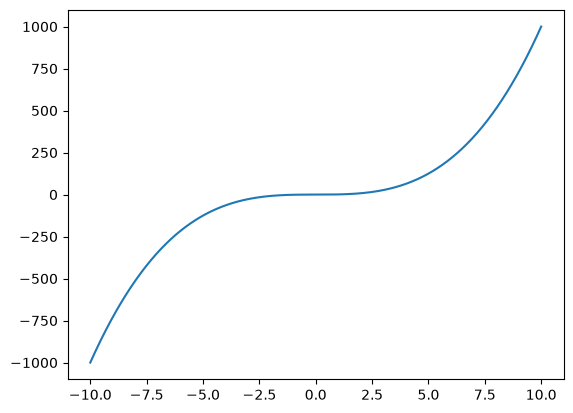

In [47]:
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 1000)
y = x ** 3

plt.plot(x, y)

Il est possible de changer des paramètres de style de la courbe avec les arguments `ls` (pour linestyle soit le style de la courbe), `lw` (pour linewidth soit la largeur de la courbe) ou encore `color` (pour la couleur de la courbe). Pour les couleurs de la courbe, vous pouvez vous référer à la [documentation](https://matplotlib.org/stable/gallery/color/named_colors.html#tableau-palette) de matplotlib pour connaître les différentes couleurs qui sont disponibles. 

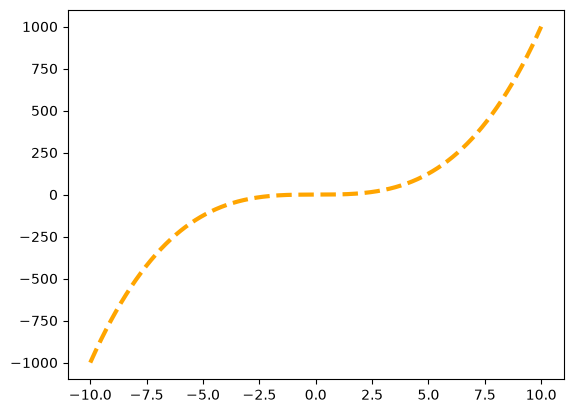

In [48]:

plt.plot(x, y, color = "orange", ls = "dashed", lw = 3)

On peut également ajouter des éléments à notre figure en changeant, par exemple, le nom des axes. Ou encore ajouter une seconde courbe qu'on peut annoter avec une légende

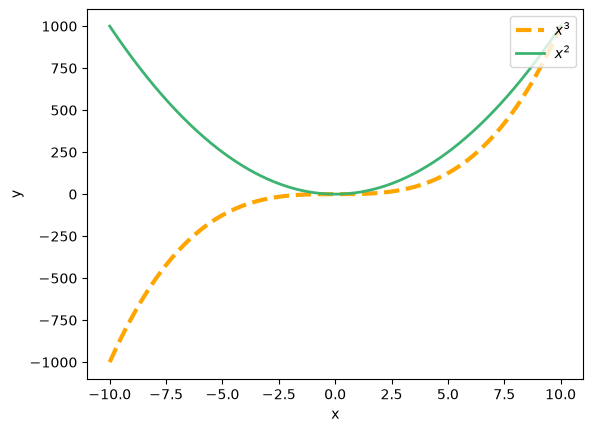

In [60]:
plt.plot(x, y, color = "orange", ls = "dashed", lw = 3, label = r"$x^3$")
plt.plot(x, 10 * x ** 2, color = "mediumseagreen", lw = 2, label = r"$x^2$")
plt.gca().set(xlabel = "x", ylabel = "y")
plt.legend(loc = "upper right")

Pour visualiser des courbes comme des distributions de probabilité, il sera utile d'ajouter des zones ombragées pour rajouter un effet visuel. Ceci peut être fait avec la fonction `plt.fill_between()`. 

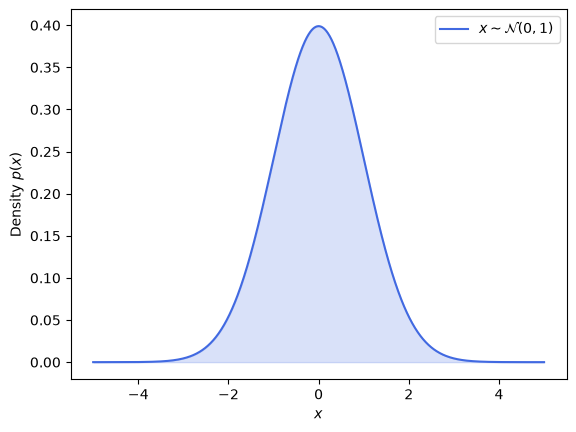

In [67]:
from scipy.stats import norm

x = np.linspace(-5, 5, 1000)
y = norm.pdf(x)

plt.plot(x, y, color = "royalblue", label = r"$x\sim \mathcal{N}(0,1)$")
plt.fill_between(x, y, alpha = 0.2, color = "royalblue")
plt.gca().set(xlabel = r"$x$", ylabel = r"Density $p(x)$")
plt.legend()

On peut aussi comparer la densité théorique d'une distribution avec la densité empirique qu'on obtient en échantillonant la distribution. Pour cela, on va devoir créer un histogramme ce qui peut être fait avec la fonction `plt.hist` de matplotlib.

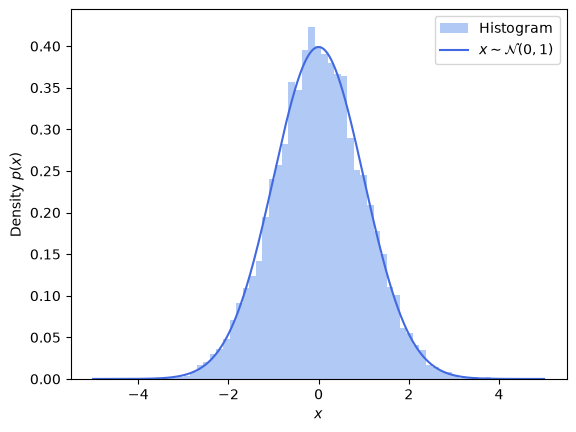

In [76]:
from scipy.stats import norm

x = np.linspace(-5, 5, 1000)

y = norm.pdf(x)
y_sampled = np.random.normal(size = int(1e4))

_ = plt.hist(y_sampled, bins = 50, alpha = 0.5, density = True, color = "cornflowerblue", label ="Histogram")
plt.plot(x, y, color = "royalblue", label = r"$x\sim \mathcal{N}(0,1)$")
plt.gca().set(xlabel = r"$x$", ylabel = r"Density $p(x)$")
plt.legend()


Il existe bien d'autres fonctionnalités à matplotlib, je vous recommande donc de chercher sur google les mots-clés de ce que vous voulez faire et il existe sûrement déjà un tutoriel. 

Pour terminer, on peut rajouter des courbes constantes en $x$ ou en $y$ avec matplotlib avec `plt.axvline` et `plt.axhline`. On peut sauvegarder la figure comme une image avec la commande `plt.savefig()`. Vous pouvez spécifier le type de fichier (png ou jpeg ou pdf par exemple) à la fin du nom du fichier. 

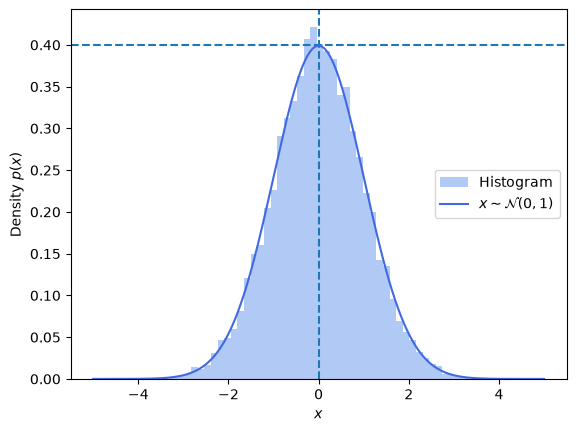

In [ ]:
x = np.linspace(-5, 5, 1000)

y = norm.pdf(x)
y_sampled = np.random.normal(size = int(1e4))

plt.axvline(0, ls = "dashed")
plt.axhline(0.4, ls = "dashed")

_ = plt.hist(y_sampled, bins = 50, alpha = 0.5, density = True, color = "cornflowerblue", label ="Histogram")
plt.plot(x, y, color = "royalblue", label = r"$x\sim \mathcal{N}(0,1)$")
plt.gca().set(xlabel = r"$x$", ylabel = r"Density $p(x)$")
plt.legend()
plt.savefig("../assets/test_fig.jpeg", bbox_inches = "tight")

### Visualisation d'images

Matplotlib est également utile pour faire de la visualisation d'images. Il est très important que vous soyez familier avec les sections de code ci-dessous parce que vous allez les utiliser très souvent dans le dernier axe du cours sur l'intelligence artificielle. 

Commençons par utiliser une image sur le web que vous reconnaîtrez peut-être. On pourra utiliser la fonction `plt.imread` de matplotlib pour lire une image (jpeg, png etc...)

In [132]:
data = plt.imread("data/sauron_eye.jpg")

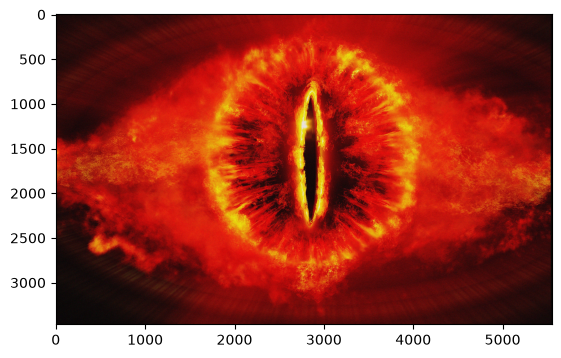

In [133]:
plt.imshow(data)

In [134]:
print(data.shape)

(3468, 5550, 3)


Comme vous pouvez le voir, l'image a trois dimensions. La première correspond au nombre de pixels verticalement, la seconde au nombre de pixels horizontalement et la dernière au nombre de canaux de couleurs. On peut visualiser les différents canaux de couleurs par indexation.

De plus, la fonction `plt.subplots` de matplotlib va nous permettre de créer une figure avec plusieurs sous-figures.

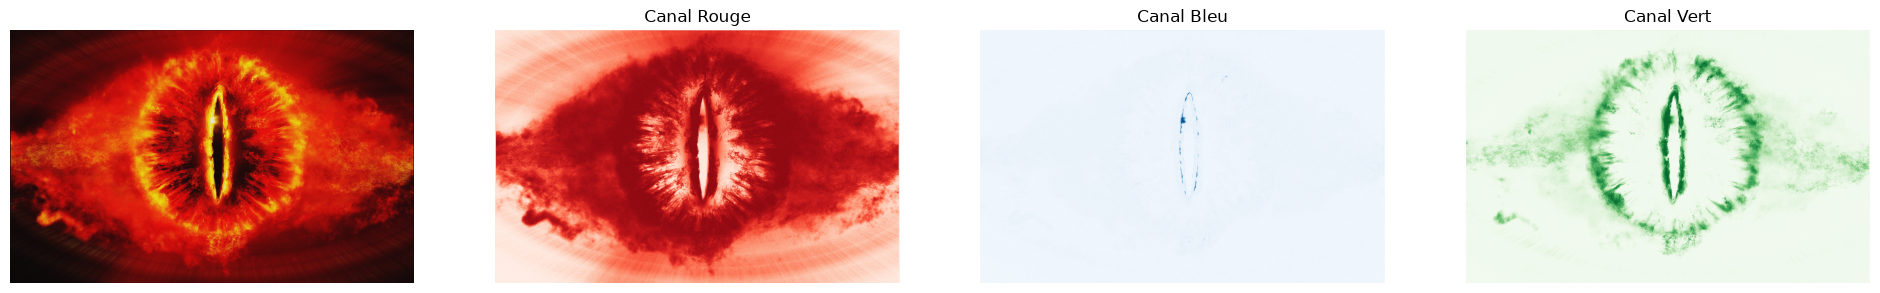

In [140]:
# 

fig, axs = plt.subplots(1, 4, figsize = (4 * 6, 4))

ax = axs[0]
ax.imshow(data)

img_red = data[...,0]
img_green = data[..., 1]
img_blue = data[..., -1]

ax = axs[1]
ax.imshow(img_red, cmap = "Reds")
ax.set_title("Canal Rouge")

ax = axs[2]
ax.imshow(img_blue, cmap = "Blues")
ax.set_title("Canal Bleu")

ax = axs[3]
ax.imshow(img_green, cmap = "Greens")
ax.set_title("Canal Vert")


# To disable the ticks of pixels for the width and height of the image
for ax in axs:
    ax.axis("off")

Pour faire de la science, il sera important de voir les unités des pixels. Ceci peut être fait avec une barre de couleurs qu'on ajoute à l'image. 

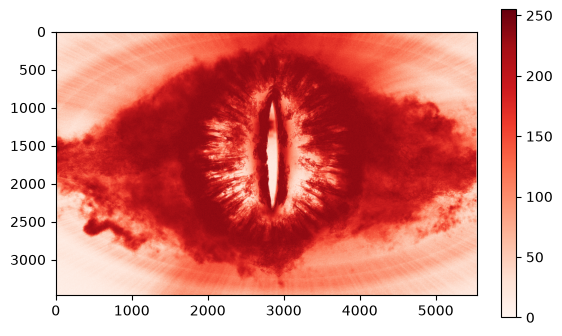

In [ ]:
fig, axs = plt.subplots(1, 1, figsize = (6, 4))

im = axs.imshow(img_red, cmap = "Reds")
plt.colorbar(im, fraction = 0.043)

Une dernière astuce utile sera de changer la norme des pixels afin d'avoir plus de détails. 

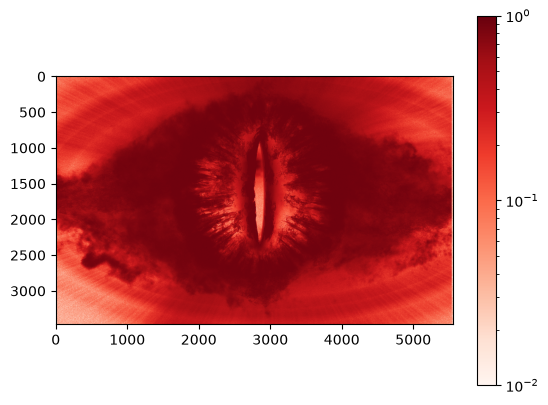

In [153]:
from matplotlib.colors import LogNorm

norm = LogNorm(vmin = 1e-2, vmax = 1e0, clip = True)
img = img_red / 255 # make it a number between 0 and 1 

plt.imshow(img, cmap = "Reds", norm = norm)
plt.colorbar()
